# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Bima Satriawan | 5054251031 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

In [3]:
import pandas as pd

df = pd.read_csv('Live.csv')
print(df.shape)
print(df.dtypes)
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.columns[df.isnull().all()])

(7050, 16)
status_id             int64
status_type             str
status_published        str
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64
dtype: object
         status_id  num_reactions  num_comments   num_shares    num_likes  \
count  7050.000000    7050.000000   7050.000000  7050.000000  7050.000000   
mean   3525.500000     230.117163    224.356028    40.022553   215.043121   
std    2035.304031     462.625309    889.636820   131.599965   449.472357   
min       1.000000       0.000000      0.000000     0.000000     0.000000   
25%    1763.250000      17.000000      0.000000     0.000000    17.000000   
50%    3525.500000      59.500000      4.000000     0.000000    5

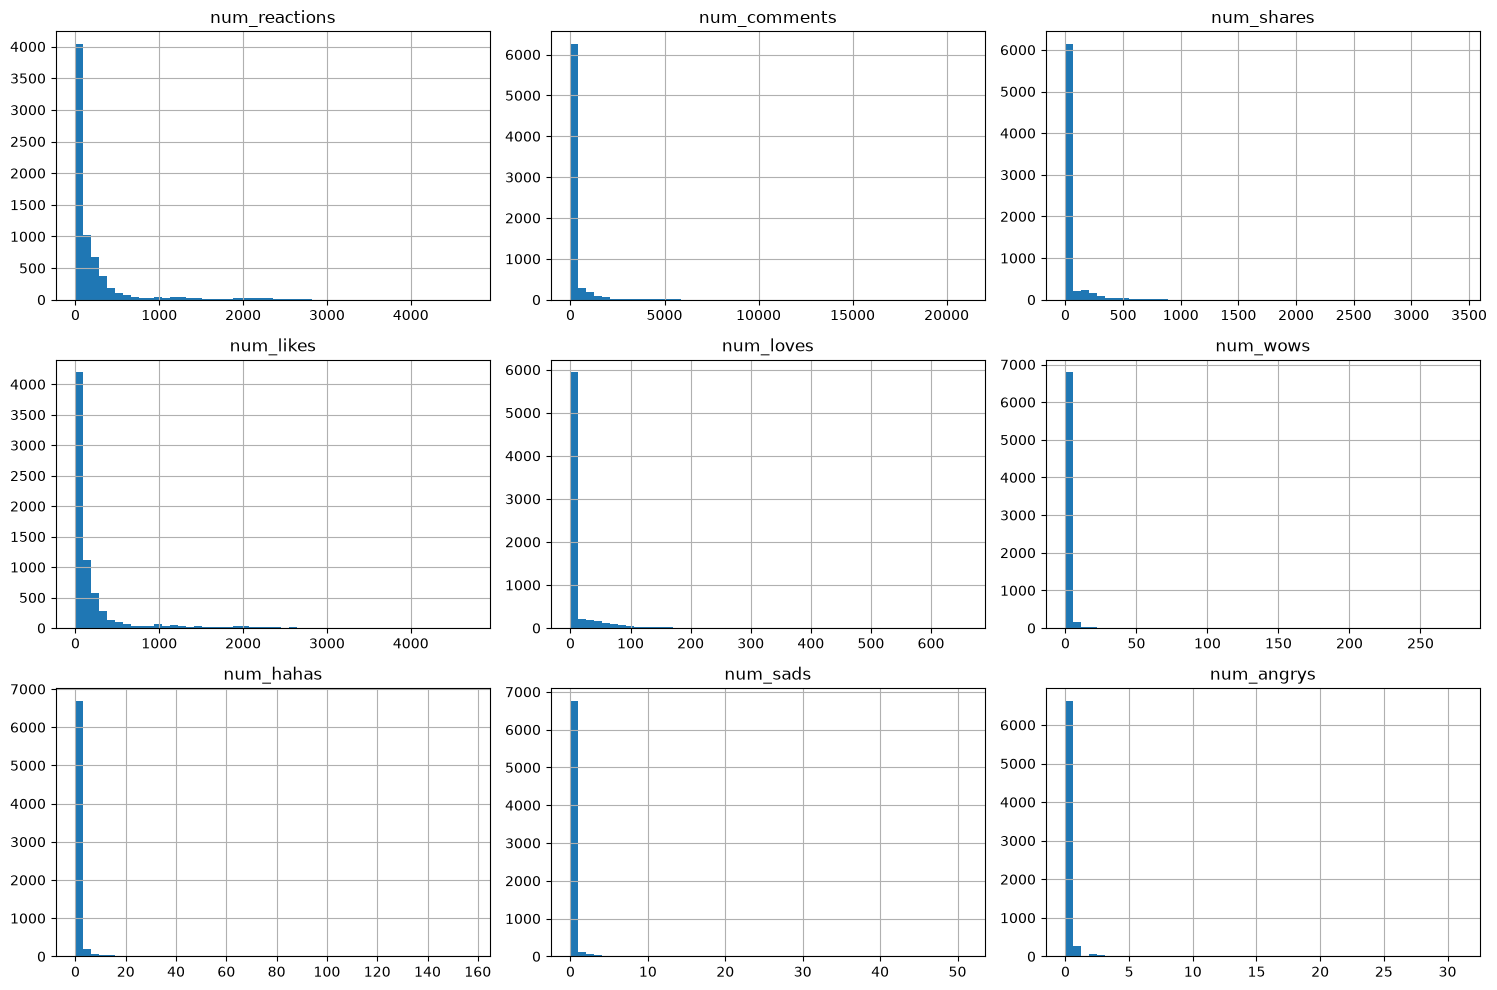

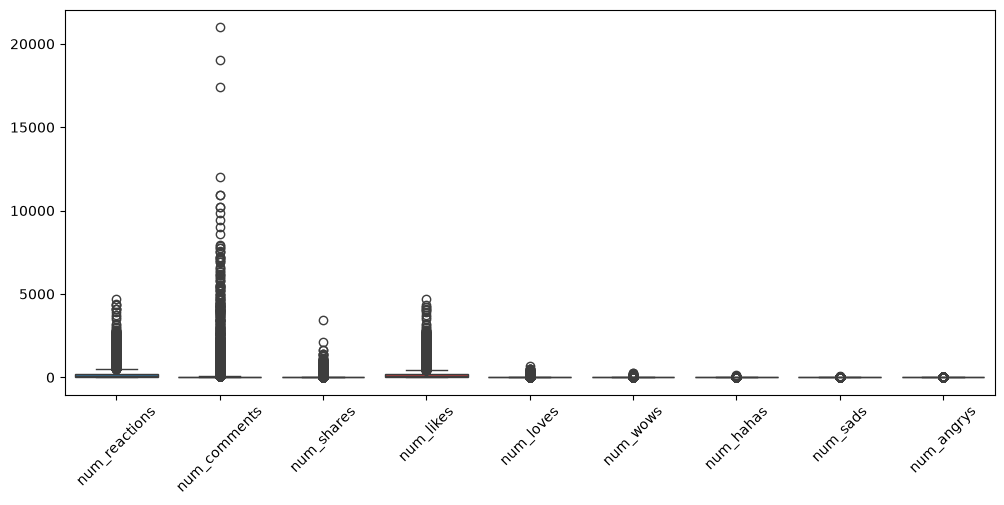

In [4]:
count_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df[count_cols].hist(figsize=(15, 10), bins=50)
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[count_cols])
plt.xticks(rotation=45)
plt.show()

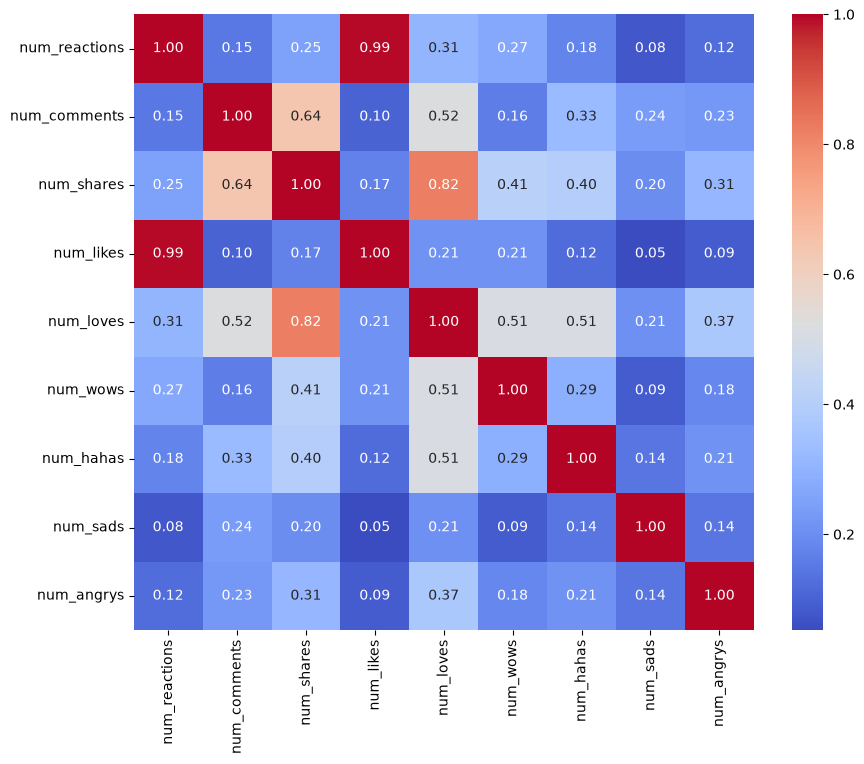

In [5]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [6]:
df['status_published'] = pd.to_datetime(df['status_published'])
df['year'] = df['status_published'].dt.year
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['has_emoji'] = (df[emoji_cols].sum(axis=1) > 0)
yearly = df.groupby('year').agg(num_posts=('status_id', 'count'), prop_emoji=('has_emoji', 'mean')).reset_index()
print(yearly)

   year  num_posts  prop_emoji
0  2012        589    0.000000
1  2013        500    0.000000
2  2014        233    0.000000
3  2015        337    0.000000
4  2016        588    0.680272
5  2017       2253    0.541944
6  2018       2550    0.577647


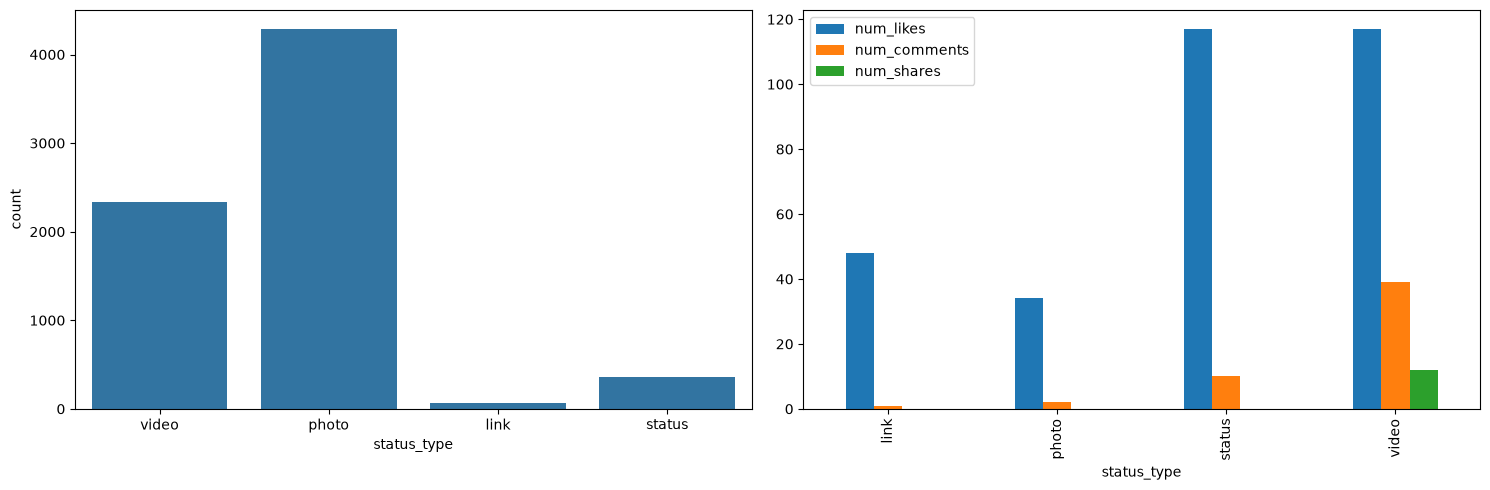

             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x='status_type', ax=axes[0])
df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median().plot(kind='bar', ax=axes[1])
plt.tight_layout()
plt.show()
print(df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median())

Berdasarkan eksplorasi awal, dapat dilihat bahwa fitur hitungan memiliki distribusi yang sangat miring ke kanan dengan banyak nilai nol, terutama pada reaksi emoji. Terdapat korelasi yang sangat tinggi antara `num_reactions` dan `num_likes` (0.99), sehingga salah satunya dapat dihapus untuk menghindari redundansi. Pola engagement juga berbeda nyata antar `status_type`, di mana video dan status memiliki median likes dan komentar yang jauh lebih tinggi dibandingkan photo dan link. Selain itu, penggunaan reaksi emoji baru mulai muncul dan signifikan pada tahun 2016 ke atas. Eksplorasi tambahan menunjukkan adanya outlier ekstrem pada jumlah komentar dan share, yang perlu ditangani pada tahap preprocessing.

# 2. Preprocessing

In [8]:
df = df.drop(columns=['status_id'])
df = df.dropna(subset=['status_published'])
df = df.drop_duplicates()

cols_to_drop = ['num_reactions', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df = df.drop(columns=cols_to_drop)

print(df.shape)
print(df.isnull().sum().sum())

(6996, 12)
27984


**Fitur yang dipilih untuk clustering:** num_likes, num_comments, num_shares, dan num_loves.

Kolom `num_reactions` dihapus karena redundan (merupakan penjumlahan dari likes dan emoji, serta memiliki korelasi 0.99 dengan num_likes). Reaksi emoji lainnya (wows, hahas, sads, angrys) juga dihapus karena sebagian besar bernilai nol, sangat jarang, dan tidak representatif jika dimasukkan ke dalam perhitungan jarak. Fitur yang dipilih sudah mewakili engagement utama. Missing value ditangani dengan mengisi nilai 0 karena ketiadaan interaksi pada fitur hitungan dapat diasumsikan sebagai nol. Outlier ekstrem akan ditangani pada tahap transformasi log berikutnya.

In [9]:
df.fillna(0, inplace=True)
features = ['num_likes', 'num_comments', 'num_shares', 'num_loves']
X = df[features].copy()
metadata = df[['status_type', 'status_published']].copy()
print(X.shape)
print(X.isnull().sum().sum())

(6996, 4)
0


**Fitur yang dipilih untuk clustering:** (isi daftar fitur yang kalian pilih beserta alasannya, termasuk keputusan terhadap kolom yang redundan atau banyak bernilai nol)

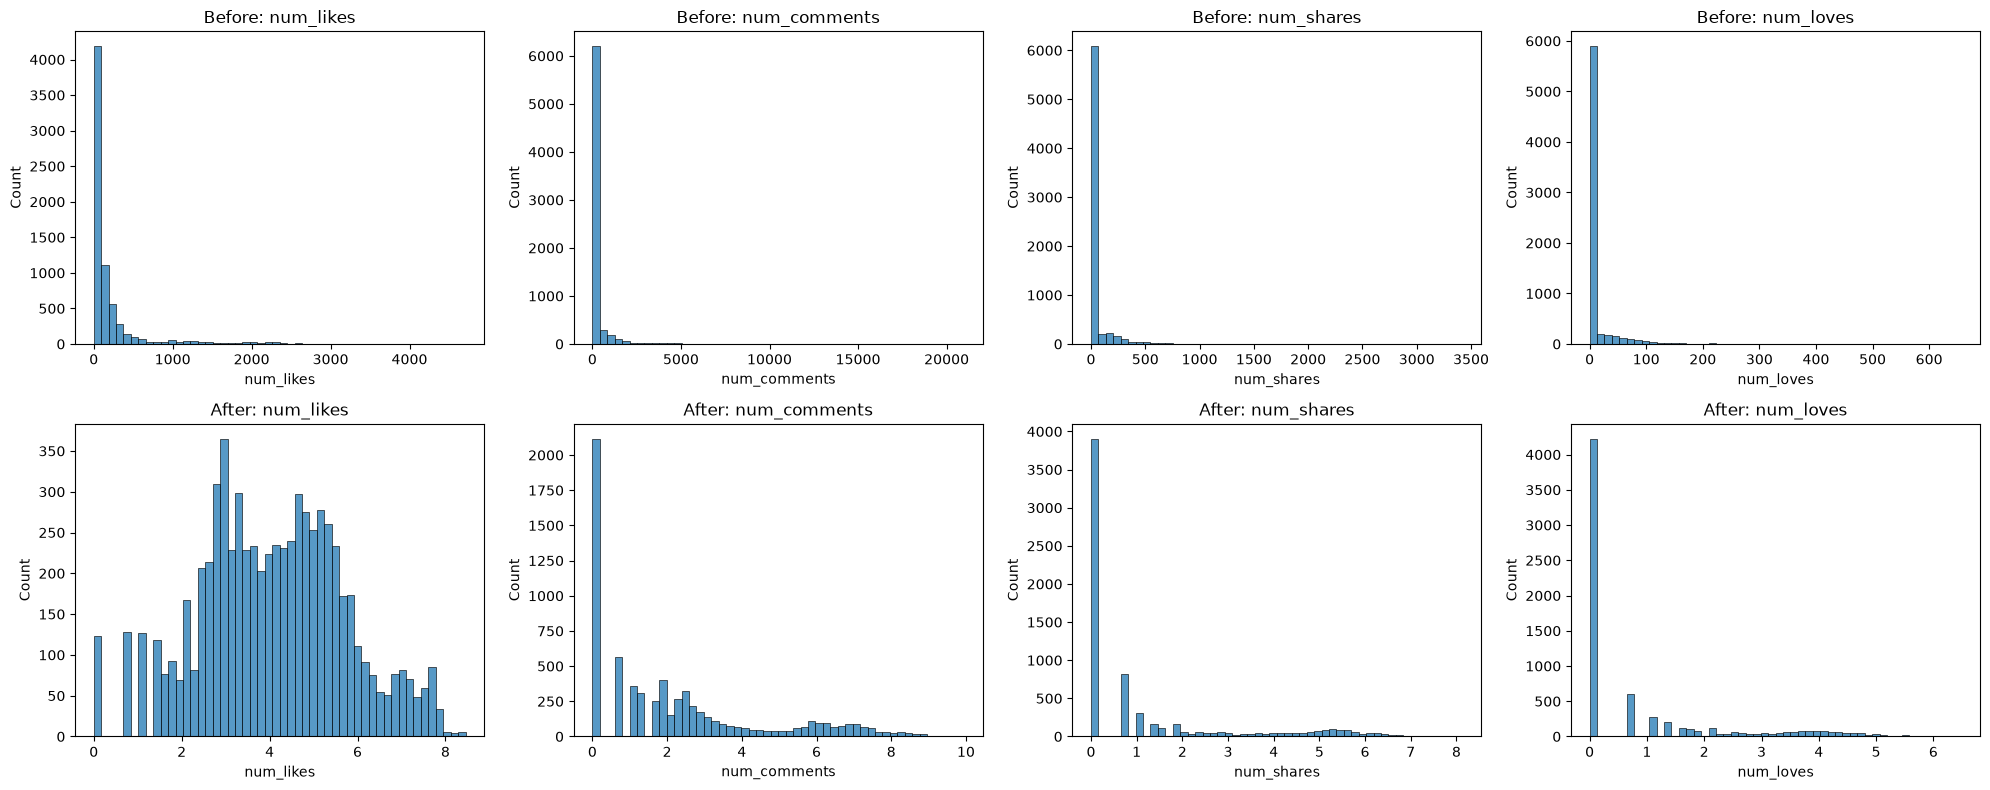

In [10]:
X_log = np.log1p(X)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, col in enumerate(features):
    sns.histplot(X[col], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f'Before: {col}')
    sns.histplot(X_log[col], bins=50, ax=axes[1, i])
    axes[1, i].set_title(f'After: {col}')
plt.tight_layout()
plt.show()

In [11]:
scaler = StandardScaler()
X_raw = X.copy()
X_raw_scaled = scaler.fit_transform(X_raw)
X_log_scaled = scaler.fit_transform(X_log)
print(X_raw.shape, X_raw_scaled.shape, X_log_scaled.shape)

(6996, 4) (6996, 4) (6996, 4)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw)
kmeans_raw_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw_scaled)
kmeans_log_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_log_scaled)
print("Raw sizes:", np.bincount(kmeans_raw.labels_))
print("Raw scaled sizes:", np.bincount(kmeans_raw_scaled.labels_))
print("Log scaled sizes:", np.bincount(kmeans_log_scaled.labels_))
print("Silhouette Raw:", silhouette_score(X_log_scaled, kmeans_raw.labels_))
print("Silhouette Raw Scaled:", silhouette_score(X_log_scaled, kmeans_raw_scaled.labels_))
print("Silhouette Log Scaled:", silhouette_score(X_log_scaled, kmeans_log_scaled.labels_))

Raw sizes: [6392  137  467]
Raw scaled sizes: [6263  360  373]
Log scaled sizes: [1103 2217 3676]
Silhouette Raw: 0.27617699471145374
Silhouette Raw Scaled: 0.2564422811314357
Silhouette Log Scaled: 0.469841376313358


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [13]:
inertias = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_log_scaled)
    inertias.append(kmeans.inertia_)
print(inertias)

[11345.59681809606, 6536.5266183647755, 5419.546063824711, 4686.806271999104, 4137.499546958975, 3709.5043616548564, 3352.0806918418302, 3035.7098167449294, 2817.9821385973796]


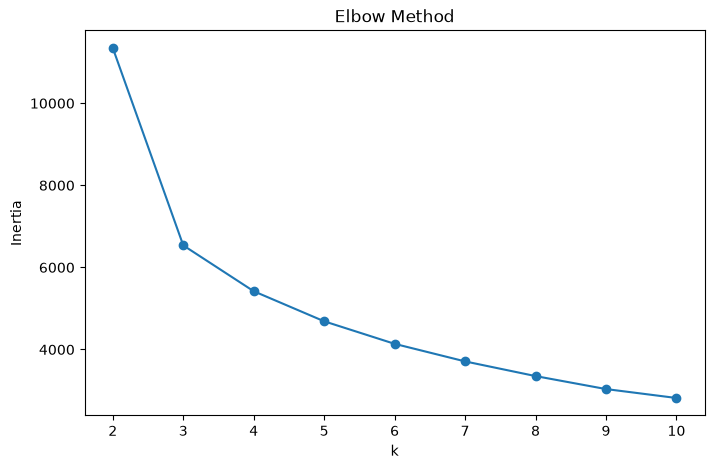

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [15]:
sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_log_scaled)
    sil_scores.append(silhouette_score(X_log_scaled, labels))
print(sil_scores)

[0.6047140803158587, 0.469841376313358, 0.34582645172083887, 0.35545053338708554, 0.35034963640129396, 0.3352304147305156, 0.31729856943921514, 0.33200523503253004, 0.3169334575925265]


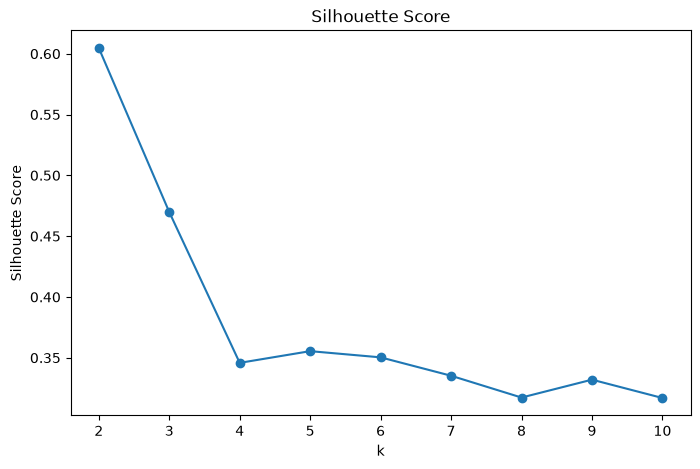

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), sil_scores, marker='o')
plt.title('Silhouette Score')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.show()

Pilihan k untuk K-Means: k = 3

Berdasarkan grafik Elbow Method, penurunan nilai inertia mulai melandai setelah k=3. Meskipun Silhouette Score tertinggi berada pada k=2, nilai pada k=3 masih tergolong baik yaitu sekitar 0.47. Memilih k=3 memberikan keseimbangan antara metrik evaluasi dan tingkat granularitas yang lebih baik untuk menginterpretasikan perilaku pengguna, dibandingkan dengan k=2 yang mungkin terlalu general.

## 3.4 Model K-Means Final

In [28]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_final.fit(X_log_scaled)
kmeans_labels = kmeans_final.labels_

In [29]:
df_kmeans = X.copy()
df_kmeans['cluster'] = kmeans_labels
print(df_kmeans.groupby('cluster').agg(['median', 'mean', 'count']))

        num_likes                   num_comments                     \
           median        mean count       median         mean count   
cluster                                                               
0           168.0  290.984587  1103        760.0  1363.368994  1103   
1           213.0  479.935047  2217         11.0    30.212449  2217   
2            18.0   22.971980  3676          0.0     2.138738  3676   

        num_shares                   num_loves                   
            median        mean count    median       mean count  
cluster                                                          
0            183.0  243.383500  1103      52.0  74.488667  1103  
1              1.0    5.091565  2217       1.0   2.935949  2217  
2              0.0    0.552231  3676       0.0   0.157236  3676  


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [30]:
Z = linkage(X_log_scaled, method='ward')
print(Z.shape)

(6995, 4)


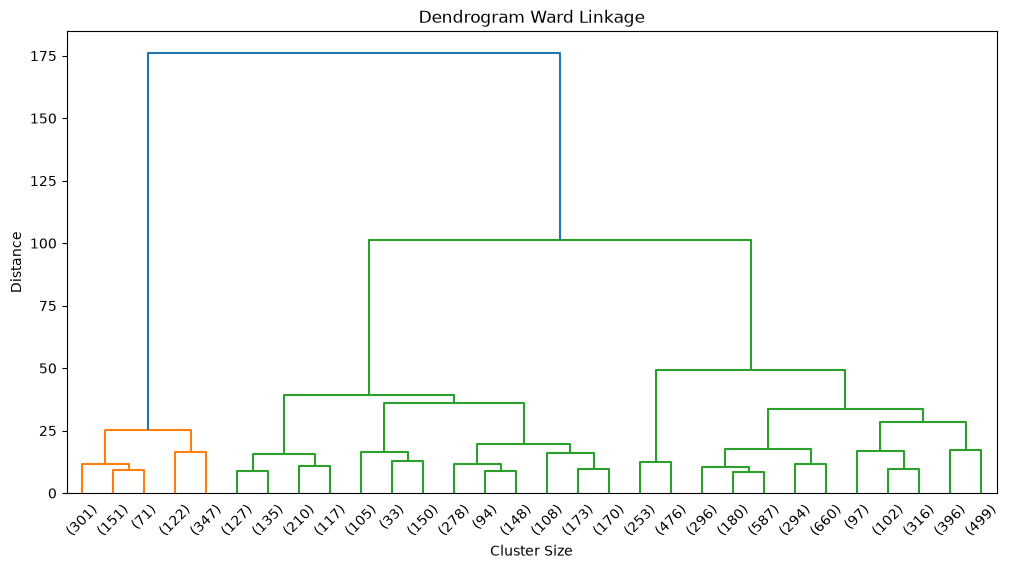

In [31]:
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title('Dendrogram Ward Linkage')
plt.xlabel('Cluster Size')
plt.ylabel('Distance')
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [32]:
linkage_methods = ['ward', 'complete', 'average', 'single']
hc_results = {}
for method in linkage_methods:
    hc = AgglomerativeClustering(n_clusters=3, linkage=method)
    hc_results[method] = hc.fit_predict(X_log_scaled)

In [33]:
comparison = []
for method, labels in hc_results.items():
    sil = silhouette_score(X_log_scaled, labels)
    counts = pd.Series(labels).value_counts().sort_index().tolist()
    comparison.append({'Linkage': method, 'Silhouette': sil, 'C0': counts[0], 'C1': counts[1], 'C2': counts[2]})
df_compare = pd.DataFrame(comparison)
print(df_compare)

    Linkage  Silhouette    C0    C1    C2
0      ward    0.452501  4156   992  1848
1  complete    0.438412  1475   875  4646
2   average    0.497459   987  5975    34
3    single    0.315297  6994     1     1


**Pilihan linkage untuk Hierarchical Clustering:** ward

Walaupun average linkage memiliki Silhouette Score tertinggi, metode tersebut menghasilkan satu cluster yang sangat kecil, yaitu hanya berisi 34 anggota. Single linkage sangat tidak cocok karena mengalami efek chaining, di mana hampir seluruh data bergabung ke dalam satu cluster besar dan menyisakan titik-titik tunggal. Ward linkage dipilih karena menghasilkan ukuran cluster yang lebih seimbang dan kompak, menyerupai hasil dari K-Means, sehingga jauh lebih masuk akal untuk diinterpretasikan.

## 4.3 Model Hierarchical Clustering Final

In [34]:
hc_final = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_labels = hc_final.fit_predict(X_log_scaled)

In [35]:
df_hc = X.copy(); df_hc['cluster'] = hc_labels; print(df_hc.groupby('cluster').agg(['median', 'mean', 'count']))

        num_likes                   num_comments                     \
           median        mean count       median         mean count   
cluster                                                               
0            21.0   36.502166  4156          1.0     2.868383  4156   
1           170.0  285.487903   992        867.5  1492.325605   992   
2           261.5  559.799784  1848         15.0    46.715909  1848   

        num_shares                   num_loves                   
            median        mean count    median       mean count  
cluster                                                          
0              0.0    1.474976  4156       0.0   0.203561  4156  
1            196.5  261.909274   992      57.0  81.030242   992  
2              1.0    8.563853  1848       2.0   4.339827  1848  


# 5. Evaluasi Model

In [36]:
metrics = []
for name, labels in [('K-Means', kmeans_labels), ('Hierarchical', hc_labels)]:
    metrics.append({
        'Model': name,
        'Silhouette': silhouette_score(X_log_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_log_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, labels)
    })
print(pd.DataFrame(metrics))

          Model  Silhouette  Davies-Bouldin  Calinski-Harabasz
0       K-Means    0.469841        0.810187       11472.645614
1  Hierarchical    0.452501        0.857049        9795.604911


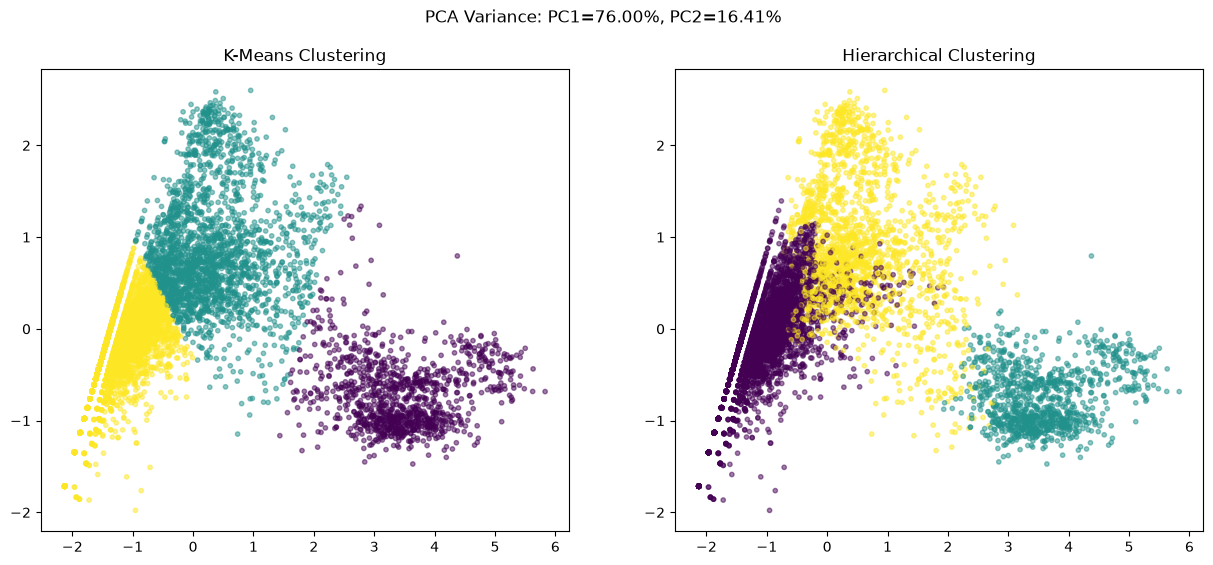

In [37]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log_scaled)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5, s=10)
axes[0].set_title('K-Means Clustering')
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=hc_labels, cmap='viridis', alpha=0.5, s=10)
axes[1].set_title('Hierarchical Clustering')
var_ratio = pca.explained_variance_ratio_
plt.suptitle(f'PCA Variance: PC1={var_ratio[0]:.2%}, PC2={var_ratio[1]:.2%}')
plt.show()

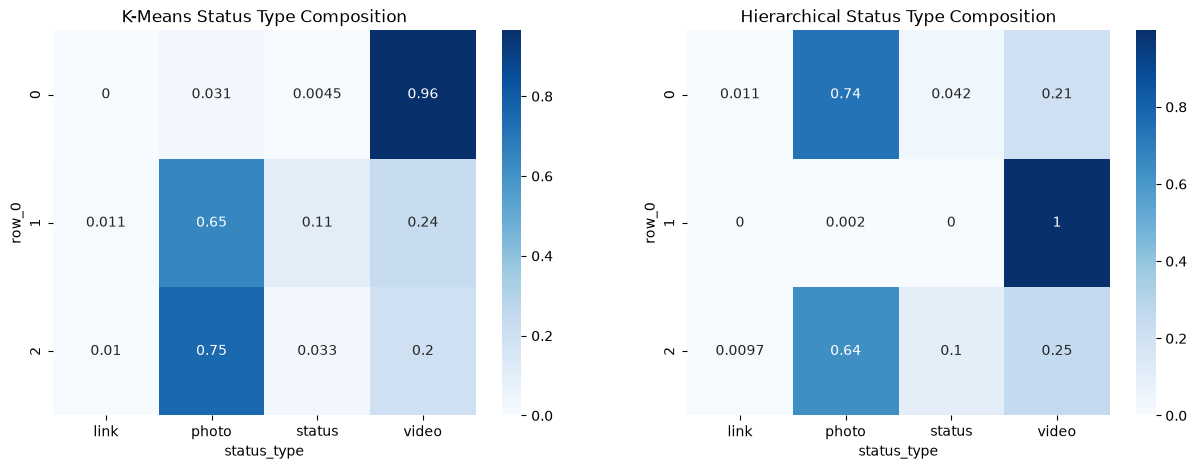

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ct_kmeans = pd.crosstab(kmeans_labels, metadata['status_type'], normalize='index')
ct_hc = pd.crosstab(hc_labels, metadata['status_type'], normalize='index')
sns.heatmap(ct_kmeans, annot=True, cmap='Blues', ax=axes[0])
axes[0].set_title('K-Means Status Type Composition')
sns.heatmap(ct_hc, annot=True, cmap='Blues', ax=axes[1])
axes[1].set_title('Hierarchical Status Type Composition')
plt.show()

# 6. Analisis

### Analisis Hasil Eksperimen

Transformasi log dan feature scaling terbukti sangat krusial pada K-Means. Pada data mentah tanpa scaling, fitur dengan nilai ekstrem seperti num_comments mendominasi perhitungan jarak, sehingga menghasilkan satu cluster raksasa dan dua cluster yang sangat kecil. Setelah diterapkan log1p untuk meredam skewness dan StandardScaler untuk menyamakan skala, hasil clustering menjadi jauh lebih seimbang dan Silhouette Score meningkat dari 0.27 menjadi 0.47. Hal ini menunjukkan bahwa algoritma berbasis jarak sangat rentan terhadap perbedaan skala dan outlier ekstrem.

Untuk mengatasi redundansi dan data sparse, kolom num_reactions dihapus karena korelasinya mencapai 0.99 dengan num_likes. Reaksi emoji lain seperti wows, hahas, sads, dan angrys juga dihapus karena mayoritas bernilai nol, yang dapat mengganggu perhitungan jarak. Hanya num_loves yang dipertahankan karena merepresentasikan emosi positif yang cukup umum terjadi.

Penentuan jumlah cluster optimal menunjukkan hasil yang sedikit berbeda antara Elbow Method dan Silhouette Score. Elbow Method menunjukkan titik siku pada k=3, sementara Silhouette Score tertinggi berada pada k=2. Nilai k=3 dipilih karena memberikan granularitas yang lebih baik untuk segmentasi bisnis, memisahkan postingan dengan engagement sedang dan rendah, meskipun metrik matematisnya sedikit lebih rendah dari k=2.

Pada Hierarchical Clustering, perbandingan metode linkage menunjukkan perbedaan yang kontras. Single linkage menghasilkan chaining effect yang parah, di mana hampir seluruh data (6994 baris) bergabung menjadi satu cluster dan menyisakan dua titik tunggal. Average linkage memiliki skor Silhouette tertinggi tetapi menghasilkan satu cluster yang sangat kecil (34 anggota). Ward linkage dipilih karena menghasilkan ukuran cluster yang paling seimbang dan kompak.

Perbandingan performa antara K-Means dan Hierarchical Clustering menunjukkan bahwa K-Means sedikit lebih unggul pada seluruh metrik internal (Silhouette, Davies-Bouldin, dan Calinski-Harabasz). Visualisasi PCA juga memperlihatkan bahwa cluster K-Means sedikit lebih rapat dan terpisah dengan baik dibandingkan Hierarchical Clustering, meskipun keduanya menangkap pola pengelompokan yang serupa.

Berdasarkan profil median dan komposisi status_type, karakteristik tiap cluster dapat dijelaskan sebagai berikut. Cluster 0 dari K-Means didominasi oleh video (96%) dengan engagement yang sangat tinggi, baik dari sisi komentar maupun share, sehingga cocok dijuluki Video Viral. Cluster 1 didominasi oleh foto (65%) dengan jumlah likes yang lumayan tinggi namun komentar dan share yang rendah, cocok dijuluki Foto Populer. Cluster 2 juga didominasi foto (75%) namun dengan engagement yang sangat rendah di semua aspek, cocok dijuluki Postingan Sepi.

Kelebihan K-Means adalah kecepatan komputasinya dan kemampuannya menangani dataset besar dengan efisien, namun pengguna harus menentukan nilai k di awal dan asumsinya terhadap bentuk cluster cenderung sferis. Hierarchical Clustering tidak memerlukan penentuan k di awal karena jumlah cluster bisa dilihat dari pemotongan dendrogram, tetapi memiliki kompleksitas waktu dan memori yang lebih tinggi serta sangat sensitif terhadap noise dan metode linkage yang dipilih.

# 7. Kesimpulan dan Saran

### Kesimpulan dan Saran

Eksperimen ini menunjukkan bahwa pemrosesan awal berupa transformasi log dan standardisasi sangat wajib dilakukan pada data engagement media sosial yang sangat miring dan penuh outlier. K-Means dengan k=3 dan Hierarchical Clustering dengan Ward linkage berhasil membagi data menjadi tiga segmen yang bermakna, yaitu postingan video dengan engagement tinggi, foto dengan engagement sedang, dan foto dengan engagement rendah. Secara keseluruhan, K-Means memberikan performa metrik yang sedikit lebih baik dan waktu komputasi yang lebih cepat dibandingkan Hierarchical Clustering.

Saran untuk eksperimen selanjutnya adalah melakukan clustering secara terpisah berdasarkan status_type agar pola engagement antar jenis konten dapat dianalisis secara lebih spesifik.